# DBSCAN

# For more info click the link below

https://docs.google.com/document/d/18iVDNbLoaLcOm2lDKUDMC6LMssuRIIiRETWmQbQdMqs/edit?usp=sharing

# Notes and interview question and answer

https://docs.google.com/document/d/19HI0bGgnVu02DXOdZVUn7JFnLVeflGBic8Sp1h6ayzc/edit?usp=sharing

# Coding

# Import libraries 

In [1]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_moons                 # Generate non-linear clustering data
from sklearn.cluster import DBSCAN                      # DBSCAN clustering algorithm
from sklearn.preprocessing import StandardScaler        # Standardize features

# Generate the dataset 

In [3]:
X, y = make_moons(
    n_samples=500,                                      # Generate 500 observations
    noise=0.08,                                         # Add a small amount of random noise
    random_state=42                                     # Make the dataset reproducible
)

print("Dataset shape:", X.shape)                       # 500 samples × 2 features

Dataset shape: (500, 2)


# Visualize the original data 

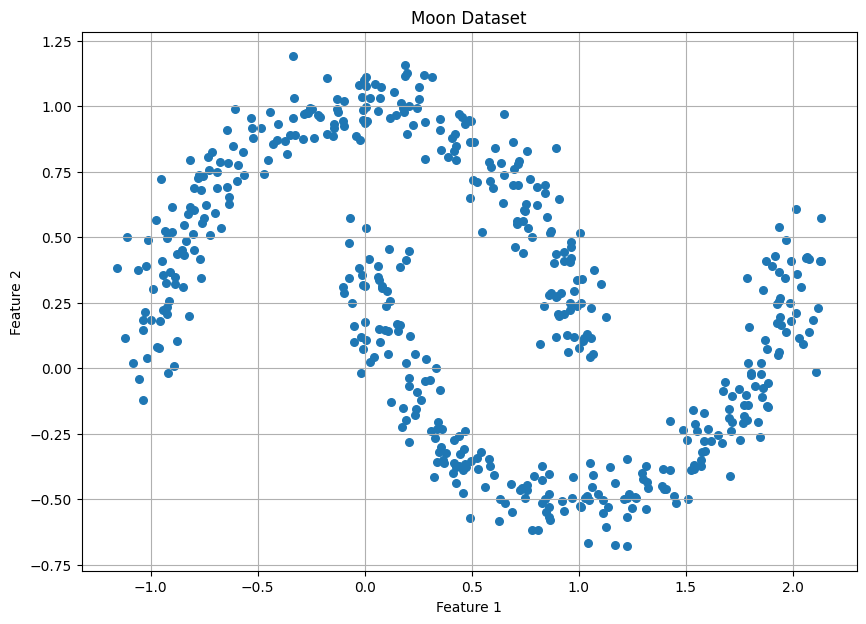

In [4]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Moon Dataset")

plt.grid()
plt.show()

# Scale the data 

In [5]:
scaler = StandardScaler()                                # Create the feature scaler

X_scaled = scaler.fit_transform(
    X                                                     # Standardize both features
)

# Create DBSCAN 

In [6]:
dbscan = DBSCAN(
    eps=0.3,                                             # Maximum neighborhood distance for a point
    min_samples=5                                       # Minimum nearby points needed to form a dense region
)

# Fit DBSCAN 

In [9]:
labels = dbscan.fit_predict(
    X_scaled                                             # Discover clusters using only the feature data
)

# Remember 

#0, 1, 2, 3...
#→ Cluster IDs
#-1
#→ Noise

# coutn cluster and noise 

In [10]:
unique_labels = set(
    labels                                                # Get all unique DBSCAN labels
)

print("Labels:", unique_labels)

Labels: {np.int64(0), np.int64(1)}


# We can count the noise points . 

In [11]:
n_noise = np.sum(
    labels == -1                                         # Count observations classified as noise
)

print("Noise points:", n_noise)

Noise points: 0


`Add the number of cluster:`

In [ ]:
n_clusters = len(
    unique_labels - {-1}                                # Remove the noise label before counting clusters
)

print("Number of clusters:", n_clusters)

# Visualize DBSCAN cluster 


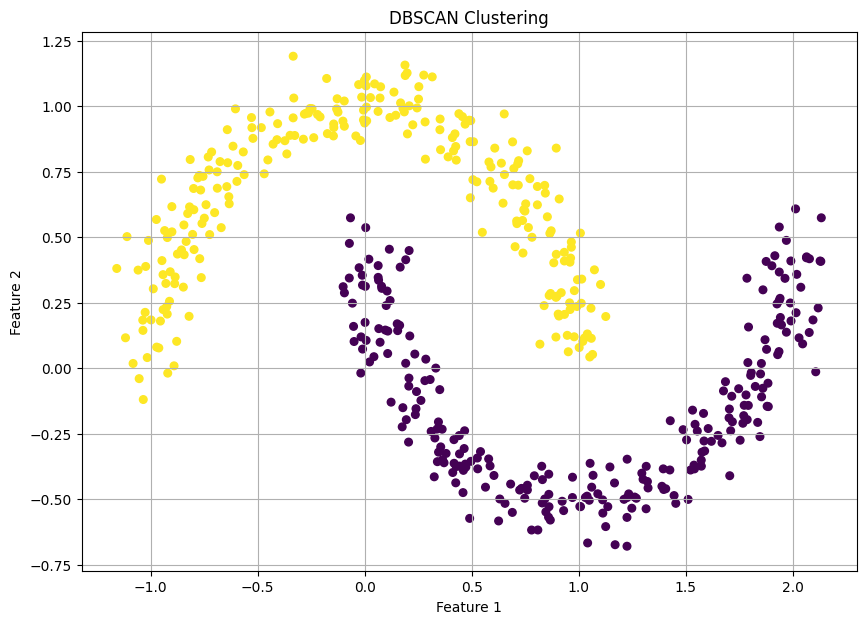

In [12]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    c=labels,                                            # Color points according to DBSCAN cluster
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN Clustering")

plt.grid()
plt.show()

# Experiment with eps

`This is the most important experiment.`

In [15]:
# You should notice that eps can dramatically change the clustering.

for eps_value in [0.1, 0.2, 0.3, 0.4, 0.5]:

    model = DBSCAN(
        eps=eps_value,                                  # Change the neighborhood radius
        min_samples=5                                   # Keep the minimum density requirement fixed
    )

    labels = model.fit_predict(
        X_scaled                                         # Cluster the standardized data
    )

    n_clusters = len(
        set(labels) - {-1}                              # Count clusters while excluding noise
    )

    n_noise = np.sum(
        labels == -1                                     # Count noise observations
    )

    print(
        f"eps={eps_value} → clusters={n_clusters}, noise={n_noise}"
    )


# eps too small
#     ↓
# Too many noise points

# eps appropriate
#     ↓
# Good clusters

# eps too large
#     ↓
# Clusters may merge

eps=0.1 → clusters=27, noise=132
eps=0.2 → clusters=2, noise=4
eps=0.3 → clusters=2, noise=0
eps=0.4 → clusters=2, noise=0
eps=0.5 → clusters=1, noise=0


# Experiment with min_samples 

In [16]:
for min_samples_value in [3, 5, 10, 20]:

    model = DBSCAN(
        eps=0.3,                                        # Keep neighborhood radius fixed
        min_samples=min_samples_value                   # Change the density requirement
    )

    labels = model.fit_predict(
        X_scaled                                         # Cluster the standardized data
    )

    n_clusters = len(
        set(labels) - {-1}                              # Count clusters excluding noise
    )

    n_noise = np.sum(
        labels == -1                                     # Count noise observations
    )

    print(
        f"min_samples={min_samples_value} → clusters={n_clusters}, noise={n_noise}"
    )

min_samples=3 → clusters=2, noise=0
min_samples=5 → clusters=2, noise=0
min_samples=10 → clusters=2, noise=1
min_samples=20 → clusters=2, noise=9


# Complete DBSCAN code 

Number of clusters: 2
Number of noise points: 0


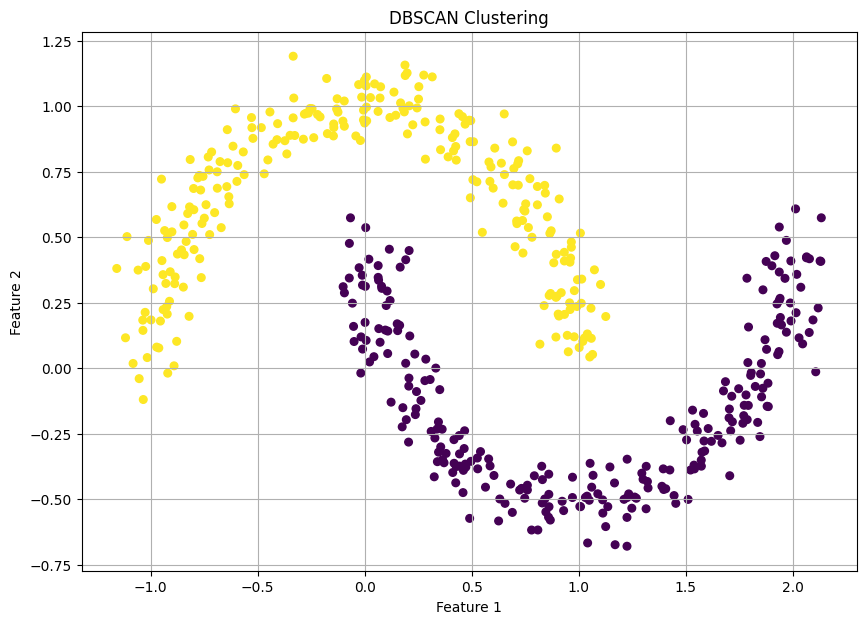

In [17]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_moons                 # Generate nonlinear clustering data
from sklearn.cluster import DBSCAN                      # DBSCAN clustering algorithm
from sklearn.preprocessing import StandardScaler        # Standardize features


X, _ = make_moons(
    n_samples=500,                                      # Generate 500 observations
    noise=0.08,                                         # Add a small amount of noise
    random_state=42                                     # Make the dataset reproducible
)


scaler = StandardScaler()                               # Create the feature scaler

X_scaled = scaler.fit_transform(
    X                                                     # Standardize the features
)


dbscan = DBSCAN(
    eps=0.3,                                             # Define the neighborhood radius
    min_samples=5                                       # Define the minimum density requirement
)


labels = dbscan.fit_predict(
    X_scaled                                             # Discover clusters without using labels
)


n_clusters = len(
    set(labels) - {-1}                                  # Count clusters while excluding noise
)

n_noise = np.sum(
    labels == -1                                         # Count observations classified as noise
)


print("Number of clusters:", n_clusters)                # Display discovered clusters
print("Number of noise points:", n_noise)               # Display detected noise


plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    c=labels,                                            # Color according to DBSCAN cluster
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN Clustering")

plt.grid()
plt.show()

# Final mental map 

                  DBSCAN
                    │
                    ↓
             Choose a point
                    │
                    ↓
          Look within radius ε
                    │
                    ↓
       Are there enough neighbors?
              /             \
            YES              NO
             ↓                ↓
        Core region       Possible noise
             │
             ↓
       Expand the cluster
             │
             ↓
       Continue until no
       more dense points